In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv('dataairquality_data.csv')
df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,6.0,18.0,5.0,9.80000,800.0,88.0,0.1,1021.1,-18.6,0.0,7,4.4,5
1,2,2013,3,1,1,6.0,15.0,5.0,11.00000,800.0,88.0,-0.3,1021.5,-19.0,0.0,7,4.0,5
2,3,2013,3,1,2,5.0,18.0,5.2,10.09936,700.0,52.0,-0.7,1021.5,-19.8,0.0,14,4.6,5
3,4,2013,3,1,3,6.0,20.0,6.0,13.60000,320.0,49.8,-1.0,1022.7,-21.2,0.0,13,2.8,5
4,5,2013,3,1,4,5.0,17.0,5.0,15.60000,600.0,73.0,-1.3,1023.0,-21.4,0.0,14,3.6,5


In [3]:
df.isna().sum()

No         0
year       0
month      0
day        0
hour       0
PM2.5      0
PM10       0
SO2        0
NO2        0
CO         0
O3         0
TEMP       0
PRES       0
DEWP       0
RAIN       0
wd         0
WSPM       0
station    0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 393630 entries, 0 to 393629
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       393630 non-null  int64  
 1   year     393630 non-null  int64  
 2   month    393630 non-null  int64  
 3   day      393630 non-null  int64  
 4   hour     393630 non-null  int64  
 5   PM2.5    393630 non-null  float64
 6   PM10     393630 non-null  float64
 7   SO2      393630 non-null  float64
 8   NO2      393630 non-null  float64
 9   CO       393630 non-null  float64
 10  O3       393630 non-null  float64
 11  TEMP     393630 non-null  float64
 12  PRES     393630 non-null  float64
 13  DEWP     393630 non-null  float64
 14  RAIN     393630 non-null  float64
 15  wd       393630 non-null  int64  
 16  WSPM     393630 non-null  float64
 17  station  393630 non-null  int64  
dtypes: float64(11), int64(7)
memory usage: 54.1 MB
None
                  No           year          month  

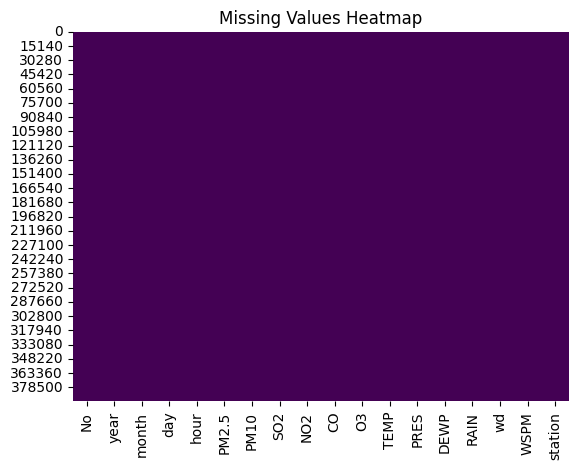

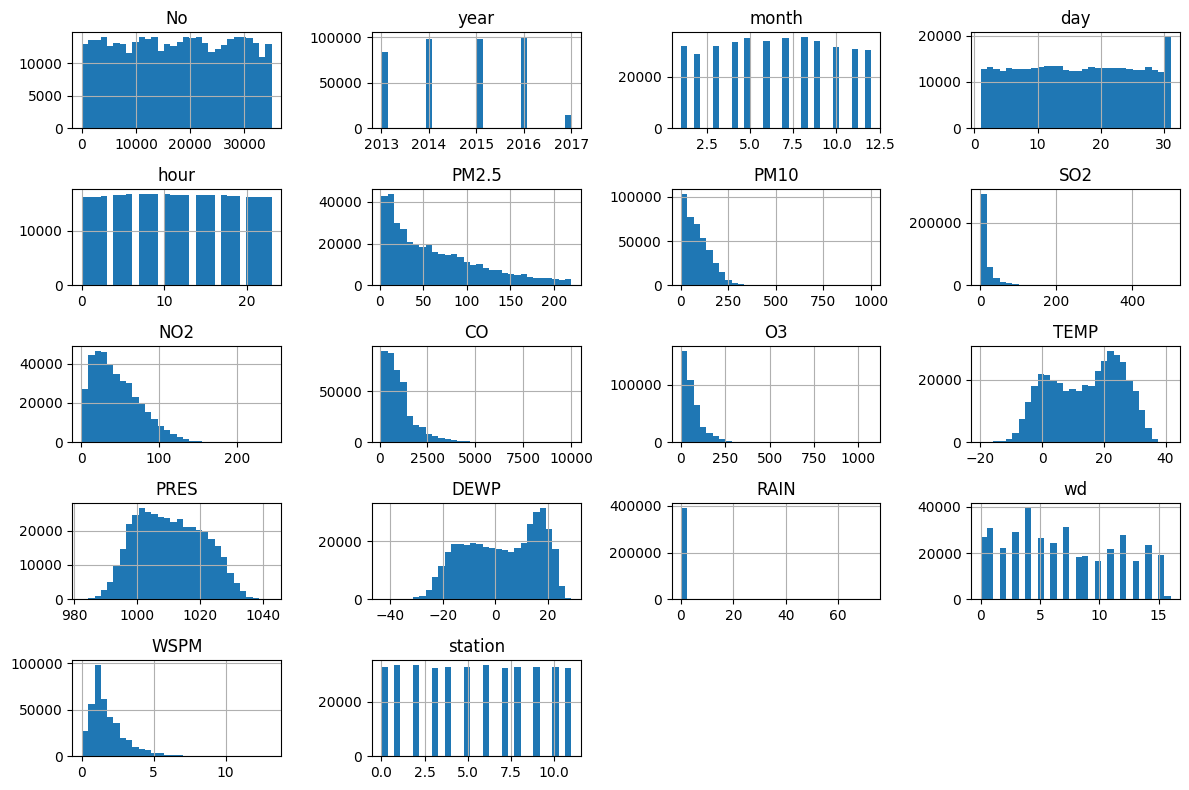

KeyboardInterrupt: 

In [ ]:
# Display basic information
print(df.info())

# Show summary statistics
print(df.describe())

# Visualize missing values
sns.heatmap(df.isna(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

# Plot distributions for numerical features
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

# Pairplot for numerical features
sns.pairplot(df.select_dtypes(include=np.number))
plt.show()

# Countplot for categorical features (if any)
categorical_cols = df.select_dtypes(include='object').columns
for col in categorical_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Countplot of {col}')
    plt.show()

# LSTM+ARIMA MODEL:

In [2]:
!pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.6 MB 3.5 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.6 MB 3.0 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.6 MB 3.1 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.6 MB 3.3 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.6 MB 2.7 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.6 MB 2.7 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.6 MB 2.9 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.6 MB 3.0 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.6 MB 3.0 MB/s eta 0:00:02
   --------------------------- ------------ 6.6/9.6 MB 3.1 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.6 MB 3.1 MB/s eta 0:00:01
   --------------

In [7]:
!pip install tensorflow ploty

Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.20.0-cp313-cp313-win_amd64.whl.metadata (4.6 kB)


ERROR: Could not find a version that satisfies the requirement ploty (from versions: none)
ERROR: No matching distribution found for ploty


In [ ]:
# aqi_forecaster_pytorch_complete.py
import pandas as pd
import numpy as np
from datetime import timedelta
import joblib
import os

# Scikit-learn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# Statsmodels (ARIMA)
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
# plotting
import matplotlib.pyplot as plt

# -------------------------
# LSTM model (multi-step)
# -------------------------
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.3, horizon=1):
        super(LSTMRegressor, self).__init__()
        self.horizon = horizon
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, horizon)  # will output 'horizon' steps

    def forward(self, x):
        # x: (batch, seq_len, features)
        out, _ = self.lstm(x)
        # take last time step hidden state and map to horizon outputs
        out = self.fc(out[:, -1, :])  # shape (batch, horizon)
        return out

class SequenceDataset(Dataset):
    def __init__(self, X, y, lookback, horizon):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.float32)
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.X) - self.lookback - self.horizon

    def __getitem__(self, idx):
        i = idx + self.lookback
        X_seq = self.X[i - self.lookback:i]
        y_seq = self.y[i:i + self.horizon]
        return torch.tensor(X_seq, dtype=torch.float32), torch.tensor(y_seq, dtype=torch.float32)

# -------------------------
# Forecaster class
# -------------------------
class AQIForecasterTorch:
    def __init__(self, lookback_window=24, forecast_horizon=168, device=None):
        self.lookback_window = lookback_window
        self.forecast_horizon = forecast_horizon  # horizon (number of timesteps predicted in one shot)
        self.arima_model = None
        self.arima_fitted = None
        self.lstm_model = None
        self.scaler_features = MinMaxScaler()
        self.scaler_target = MinMaxScaler()
        self.feature_columns = None
        self.model_history = {}
        self.predictions = {}
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    # -------------------------
    # Data loading & preprocessing
    # -------------------------
    def load_and_preprocess_data(self, filepath):
        print("Loading and preprocessing data...")
        self.data = pd.read_csv(filepath)
        print(f"Loaded {len(self.data)} records")

        # build datetime column from year, month, day, hour (assumes those columns exist)
        self.data['datetime'] = pd.to_datetime(self.data[['year', 'month', 'day', 'hour']])

        # Calculate AQI (PM2.5 and PM10 based simplified)
        self.data['AQI'] = self.calculate_aqi(
            self.data['PM2.5'], self.data['PM10'],
            self.data.get('SO2', pd.Series([np.nan] * len(self.data))),
            self.data.get('NO2', pd.Series([np.nan] * len(self.data))),
            self.data.get('CO', pd.Series([np.nan] * len(self.data))),
            self.data.get('O3', pd.Series([np.nan] * len(self.data)))
        )

        # keep valid AQI
        self.data = self.data.dropna(subset=['AQI'])
        self.data = self.data[self.data['AQI'] > 0]
        self.data = self.data.sort_values('datetime').reset_index(drop=True)

        # create features and lags
        self.create_temporal_features()
        self.create_lag_features()

        print(f"Preprocessed data shape: {self.data.shape}")
        print(f"AQI stats: min={self.data['AQI'].min():.1f}, max={self.data['AQI'].max():.1f}, mean={self.data['AQI'].mean():.1f}")
        return self.data

    def calculate_aqi(self, pm25, pm10, so2, no2, co, o3):
        def get_aqi_pm25(pm25_val):
            if pd.isna(pm25_val): return 0
            if pm25_val <= 30: return pm25_val * 50 / 30
            elif pm25_val <= 60: return 50 + (pm25_val - 30) * 50 / 30
            elif pm25_val <= 90: return 100 + (pm25_val - 60) * 100 / 30
            elif pm25_val <= 120: return 200 + (pm25_val - 90) * 100 / 30
            elif pm25_val <= 250: return 300 + (pm25_val - 120) * 100 / 130
            else: return 400

        def get_aqi_pm10(pm10_val):
            if pd.isna(pm10_val): return 0
            if pm10_val <= 50: return pm10_val * 50 / 50
            elif pm10_val <= 100: return 50 + (pm10_val - 50) * 50 / 50
            elif pm10_val <= 250: return 100 + (pm10_val - 100) * 100 / 150
            elif pm10_val <= 350: return 200 + (pm10_val - 250) * 100 / 100
            elif pm10_val <= 430: return 300 + (pm10_val - 350) * 100 / 80
            else: return 400

        aqi_pm25 = pm25.apply(get_aqi_pm25) if hasattr(pm25, 'apply') else get_aqi_pm25(pm25)
        aqi_pm10 = pm10.apply(get_aqi_pm10) if hasattr(pm10, 'apply') else get_aqi_pm10(pm10)
        if hasattr(pm25, 'apply'):
            return np.maximum(aqi_pm25, aqi_pm10)
        else:
            return max(aqi_pm25, aqi_pm10)

    def create_temporal_features(self):
        self.data['hour_sin'] = np.sin(2 * np.pi * self.data['hour'] / 24)
        self.data['hour_cos'] = np.cos(2 * np.pi * self.data['hour'] / 24)
        self.data['day_of_week'] = self.data['datetime'].dt.dayofweek
        self.data['day_sin'] = np.sin(2 * np.pi * self.data['day_of_week'] / 7)
        self.data['day_cos'] = np.cos(2 * np.pi * self.data['day_of_week'] / 7)
        self.data['month_sin'] = np.sin(2 * np.pi * self.data['month'] / 12)
        self.data['month_cos'] = np.cos(2 * np.pi * self.data['month'] / 12)

    def create_lag_features(self, lags=[1,2,3,6,12,24]):
        for lag in lags:
            self.data[f'AQI_lag_{lag}'] = self.data['AQI'].shift(lag)
            # keep original pollutant columns naming
            self.data[f'PM25_lag_{lag}'] = self.data['PM2.5'].shift(lag)
            self.data[f'PM10_lag_{lag}'] = self.data['PM10'].shift(lag)
        self.data = self.data.dropna().reset_index(drop=True)

    # -------------------------
    # Stationarity & ARIMA
    # -------------------------
    def analyze_stationarity(self, series, title="AQI"):
        print(f"\n=== Stationarity Analysis for {title} ===")
        adf_result = adfuller(series.dropna())
        print(f"ADF Statistic: {adf_result[0]:.6f}")
        print(f"p-value: {adf_result[1]:.6f}")
        for key, value in adf_result[4].items():
            print(f"\t{key}: {value:.3f}")
        return adf_result[1] <= 0.05

    def find_arima_order(self, series, max_p=3, max_q=3):
        print("\n=== Finding Optimal ARIMA Order ===")
        if not self.analyze_stationarity(series):
            series = series.diff().dropna(); d = 1
        else:
            d = 0
        best_aic = float('inf'); best_order = None; aic_results = []
        for p in range(max_p+1):
            for q in range(max_q+1):
                try:
                    model = ARIMA(series, order=(p,d,q))
                    fitted = model.fit()
                    aic = fitted.aic
                    aic_results.append((p,d,q,aic))
                    if aic < best_aic:
                        best_aic = aic; best_order = (p,d,q)
                except Exception:
                    continue
        print(f"Best ARIMA order: {best_order} (AIC: {best_aic:.2f})")
        return best_order

    def train_lstm(self, X, y, validation_split=0.2, epochs=20, batch_size=64, lr=1e-3,
               hidden_size=64, num_layers=2, dropout=0.3, patience=3, save_path='lstm_forecaster.pth'):

        # build dataset (lazy)
        dataset = SequenceDataset(X, y, self.lookback_window, self.forecast_horizon)

        val_len = int(len(dataset) * validation_split)
        train_len = len(dataset) - val_len
        train_set, val_set = random_split(dataset, [train_len, val_len])

        train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
        val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

        # build model
        input_size = X.shape[1]
        model = LSTMRegressor(input_size, hidden_size, num_layers, dropout, self.forecast_horizon).to(self.device)
        criterion = nn.SmoothL1Loss()
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        best_val_loss, patience_counter = float('inf'), 0
        history = {'train_loss': [], 'val_loss': []}

        print("\n=== Training LSTM Model (PyTorch, Lazy Dataset) ===")
        for epoch in range(1, epochs+1):
            # train
            model.train()
            train_losses = []
            for xb, yb in train_loader:
                xb, yb = xb.to(self.device), yb.to(self.device)
                optimizer.zero_grad()
                preds = model(xb)
                loss = criterion(preds, yb)
                loss.backward()
                optimizer.step()
                train_losses.append(loss.item())

            # val
            model.eval()
            val_losses = []
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(self.device), yb.to(self.device)
                    preds = model(xb)
                    loss = criterion(preds, yb)
                    val_losses.append(loss.item())

            train_loss, val_loss = np.mean(train_losses), np.mean(val_losses)
            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)
            print(f"Epoch {epoch}/{epochs} - train_loss={train_loss:.5f}, val_loss={val_loss:.5f}")

            if val_loss < best_val_loss - 1e-5:
                best_val_loss = val_loss
                torch.save(model.state_dict(), save_path)
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"⏹ Early stopping at epoch {epoch}")
                    break

        model.load_state_dict(torch.load(save_path, map_location=self.device))
        self.lstm_model = model
        self.model_history['lstm'] = history
        return model


    # -------------------------
    # Sequence creation (multi-step)
    # -------------------------
    def create_sequences(self, X, y, horizon=None):
        horizon = horizon or self.forecast_horizon
        X_seq, y_seq = [], []
        # ensure we have enough samples
        for i in range(self.lookback_window, len(X) - horizon + 1):
            X_seq.append(X[i-self.lookback_window:i])
            y_seq.append(y[i:i+horizon])   # multi-step target
        return np.array(X_seq), np.array(y_seq)

    # -------------------------
    # Prepare features (returns scaled arrays; sequences built at train time)
    # -------------------------
    def prepare_lstm_data(self, station_id=None):
        if station_id is not None:
            df = self.data[self.data['station'] == station_id].copy()
        else:
            df = self.data.copy()

        # choose features
        self.feature_columns = [
            'PM2.5','PM10','SO2','NO2','CO','O3',
            'TEMP','PRES','DEWP','RAIN','WSPM',
            'hour_sin','hour_cos','day_sin','day_cos','month_sin','month_cos'
        ]
        lag_columns = [c for c in df.columns if 'lag' in c]
        self.feature_columns.extend(lag_columns)
        # keep only columns that exist and are not heavily NaN
        self.feature_columns = [c for c in self.feature_columns if c in df.columns and df[c].notna().sum() > len(df)*0.8]

        X = df[self.feature_columns].values
        y = df['AQI'].values
        X = np.nan_to_num(X, nan=0.0)
        y = np.nan_to_num(y, nan=0.0)

        # scale
        X_scaled = self.scaler_features.fit_transform(X)
        y_scaled = self.scaler_target.fit_transform(y.reshape(-1,1)).flatten()

        print(f"LSTM raw shape: X={X_scaled.shape}, y={y_scaled.shape}, features used={len(self.feature_columns)}")
        return X_scaled, y_scaled, df

    # -------------------------
    # Train LSTM (multi-step)
    # -------------------------
    def train_lstm(self, X, y, validation_split=0.2, epochs=20, batch_size=64, lr=1e-3,
                   hidden_size=64, num_layers=2, dropout=0.3, patience=3, save_path='lstm_forecaster.pth'):
        """
        Train LSTM for multi-step forecasting. X,y should be un-sequenced arrays (scaled).
        This function builds sequences internally using self.forecast_horizon.
        """
        # 1) create sequences with current horizon
        X_seq, y_seq = self.create_sequences(X, y, horizon=self.forecast_horizon)
        if len(X_seq) == 0:
            raise ValueError("Not enough data to create sequences: reduce lookback_window or horizon.")

        # 2) train/test split (time-ordered)
        X_train, X_val, y_train, y_val = train_test_split(X_seq, y_seq, test_size=validation_split, shuffle=False)

        # 3) convert to tensors
        X_train_t = torch.tensor(X_train, dtype=torch.float32).to(self.device)
        y_train_t = torch.tensor(y_train, dtype=torch.float32).to(self.device)
        X_val_t = torch.tensor(X_val, dtype=torch.float32).to(self.device)
        y_val_t = torch.tensor(y_val, dtype=torch.float32).to(self.device)

        train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)

        # 4) model
        model = LSTMRegressor(input_size=X.shape[1], hidden_size=hidden_size, num_layers=num_layers, dropout=dropout, horizon=self.forecast_horizon).to(self.device)
        criterion = nn.SmoothL1Loss()
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        best_val_loss = float('inf')
        history = {'train_loss': [], 'val_loss': []}
        patience_counter = 0

        print("\n=== Training LSTM Model (multi-step) ===")
        for epoch in range(1, epochs+1):
            model.train()
            train_losses = []
            for xb, yb in train_loader:
                xb, yb = xb.to(self.device), yb.to(self.device)
                optimizer.zero_grad()
                preds = model(xb)                # shape (batch, horizon)
                loss = criterion(preds, yb)
                loss.backward()
                optimizer.step()
                train_losses.append(loss.item())

            model.eval()
            val_losses = []
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(self.device), yb.to(self.device)
                    preds = model(xb)
                    loss = criterion(preds, yb)
                    val_losses.append(loss.item())

            train_loss = float(np.mean(train_losses))
            val_loss = float(np.mean(val_losses))
            history['train_loss'].append(train_loss)
            history['val_loss'].append(val_loss)

            print(f"Epoch {epoch}/{epochs} - train_loss: {train_loss:.6f} - val_loss: {val_loss:.6f}")

            # early stopping & save best
            if val_loss < best_val_loss - 1e-6:
                best_val_loss = val_loss
                # save checkpoint including hyperparams
                torch.save({
                    'model_state_dict': model.state_dict(),
                    'input_size': X.shape[1],
                    'hidden_size': hidden_size,
                    'num_layers': num_layers,
                    'dropout': dropout,
                    'horizon': self.forecast_horizon
                }, save_path)
                # also save scalers
                joblib.dump(self.scaler_features, 'scaler_features.joblib')
                joblib.dump(self.scaler_target, 'scaler_target.joblib')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"⏹ Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
                    break

        # load best
        if os.path.exists(save_path):
            chk = torch.load(save_path, map_location=self.device)
            model.load_state_dict(chk['model_state_dict'])
            self.lstm_model = model
            self.model_history['lstm'] = history
            print("Loaded best model from", save_path)
            return model
        else:
            # if not saved (unlikely), assign current
            self.lstm_model = model
            self.model_history['lstm'] = history
            return model

    # -------------------------
    # Reload saved model + scalers
    # -------------------------
    def load_lstm_checkpoint(self, filepath='lstm_forecaster.pth', scaler_feat='scaler_features.joblib', scaler_tgt='scaler_target.joblib'):
        chk = torch.load(filepath, map_location=self.device)
        model = LSTMRegressor(
            input_size=chk['input_size'],
            hidden_size=chk['hidden_size'],
            num_layers=chk['num_layers'],
            dropout=chk['dropout'],
            horizon=chk['horizon']
        ).to(self.device)
        model.load_state_dict(chk['model_state_dict'])
        model.eval()
        self.lstm_model = model
        self.forecast_horizon = chk['horizon']
        # load scalers if present
        if os.path.exists(scaler_feat):
            self.scaler_features = joblib.load(scaler_feat)
        if os.path.exists(scaler_tgt):
            self.scaler_target = joblib.load(scaler_tgt)
        print(f"Loaded LSTM checkpoint (horizon={self.forecast_horizon})")
        return model

    # -------------------------
    # Hybrid forecast: ARIMA + LSTM
    # -------------------------
    def hybrid_forecast(self, steps=168):
        """
        steps = number of hours to forecast (e.g., 168 for one week).
        For correct direct LSTM multi-step, train the LSTM with horizon == steps.
        If trained horizon == steps => direct LSTM forecast in one pass.
        If trained horizon < steps => we will produce block-wise forecasts by sliding.
        """
        print(f"\n=== Generating {steps}-step Hybrid Forecast ===")
        if self.arima_fitted is None:
            raise ValueError("Train ARIMA model first (train_arima).")
        if self.lstm_model is None:
            raise ValueError("Train LSTM model first (train_lstm) or load checkpoint.")

        # ARIMA forecast (linear)
        arima_forecast = self.arima_fitted.forecast(steps=steps)

        # LSTM forecast
        # If model horizon matches requested steps => single pass
        model = self.lstm_model
        trained_horizon = getattr(model, 'horizon', self.forecast_horizon)

        if trained_horizon == steps:
            # prepare last sequence
            last_seq = self.X_test[-1:].copy()
            with torch.no_grad():
                last_seq_t = torch.tensor(last_seq, dtype=torch.float32).to(self.device)
                preds = model(last_seq_t).cpu().numpy().flatten()
            lstm_forecast = self.scaler_target.inverse_transform(preds.reshape(-1,1)).flatten()
        else:
            # block-wise approach: predict trained_horizon blocks repeatedly (fast, avoids recursive single-step)
            blocks = []
            current_seq = self.X_test[-1:].copy()  # shape (1, lookback, features)
            steps_remaining = steps
            while steps_remaining > 0:
                with torch.no_grad():
                    cur_t = torch.tensor(current_seq, dtype=torch.float32).to(self.device)
                    preds_block = model(cur_t).cpu().numpy().flatten()  # length = trained_horizon
                # inverse scale first trained_horizon entries
                preds_block_unscaled = self.scaler_target.inverse_transform(preds_block.reshape(-1,1)).flatten()
                # append only the number we need
                take = min(len(preds_block_unscaled), steps_remaining)
                blocks.extend(preds_block_unscaled[:take])
                steps_remaining -= take
                # update current_seq: roll and append preds_block (scaled) to last feature column
                # need preds in scaled space to update features
                preds_block_scaled = self.scaler_target.transform(preds_block.reshape(-1,1)).flatten()
                cur = current_seq.copy()
                # roll left along time axis and append next values (this is naive but faster than single-step)
                cur = np.roll(cur, -take, axis=1)
                # place last 'take' predicted values into the last 'take' timesteps first feature (AQI) column
                for k in range(take):
                    cur[0, -take + k, 0] = preds_block_scaled[k]
                current_seq = cur
            lstm_forecast = np.array(blocks)[:steps]

        # Combine ARIMA & LSTM via decaying weights (ARIMA stronger at short horizons)
        arima_weights = np.exp(-np.arange(steps) / 50.0)
        lstm_weights = 1 - arima_weights
        hybrid_forecast = (arima_weights * arima_forecast) + (lstm_weights * lstm_forecast)

        # build DataFrame of forecasts
        last_datetime = self.data['datetime'].iloc[-1]
        forecast_dates = [last_datetime + timedelta(hours=i+1) for i in range(steps)]

        forecast_df = pd.DataFrame({
            'datetime': forecast_dates,
            'arima_forecast': arima_forecast,
            'lstm_forecast': lstm_forecast,
            'hybrid_forecast': hybrid_forecast,
            'arima_weight': arima_weights,
            'lstm_weight': lstm_weights
        })
        self.predictions['forecast'] = forecast_df
        return forecast_df

    # -------------------------
    # Evaluation utilities
    # -------------------------
    def evaluate_model(self, y_true, y_pred, model_name="Model"):
        # allow y_true and y_pred to be sequences (multi-step) or 1D arrays
        y_true = np.array(y_true).reshape(-1)
        y_pred = np.array(y_pred).reshape(-1)
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        # stable MAPE
        mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true==0, 1e-6, y_true))) * 100.0
        print(f"\n=== {model_name} Evaluation ===")
        print(f"RMSE: {rmse:.2f}")
        print(f"MAE: {mae:.2f}")
        print(f"R²: {r2:.4f}")
        print(f"MAPE: {mape:.2f}%")
        return {'rmse': rmse, 'mae': mae, 'r2': r2, 'mape': mape}

    # -------------------------
    # Plotting (matplotlib fallback)
    # -------------------------
    def plot_forecast_comparison(self, plot_last_hours=168):
        if 'forecast' not in self.predictions:
            print("No forecast available. Run hybrid_forecast() first.")
            return
        df = self.predictions['forecast']
        hist = self.data.tail(plot_last_hours)
        plt.figure(figsize=(12,6))
        plt.plot(hist['datetime'], hist['AQI'], label='Historical AQI', linewidth=2)
        plt.plot(df['datetime'], df['arima_forecast'], label='ARIMA', linestyle='--')
        plt.plot(df['datetime'], df['lstm_forecast'], label='LSTM', linestyle=':')
        plt.plot(df['datetime'], df['hybrid_forecast'], label='Hybrid', linewidth=2)
        plt.xlabel("Datetime")
        plt.ylabel("AQI")
        plt.title("AQI Forecast Comparison")
        plt.legend()
        plt.tight_layout()
        plt.show()


# -------------------------
# Example run (how to use)
# -------------------------
if __name__ == '__main__':
    forecaster = AQIForecasterTorch(lookback_window=24, forecast_horizon=168)  # set horizon (168 = 1 week hourly)
    data = forecaster.load_and_preprocess_data('dataairquality_data.csv')

    # quick TS analysis (optional)
    aqi_series = data.set_index('datetime')['AQI'].resample('H').mean()
    forecaster.analyze_stationarity(aqi_series)

    # train ARIMA (fast: small p/q search)
    forecaster.train_arima(aqi_series, order=(1,0,5))

    # prepare LSTM input (scaled arrays)
    X_scaled, y_scaled, _ = forecaster.prepare_lstm_data()

    # split & save X_test/X_train for forecasting use later
    # Instead of precomputing all sequences (saves memory)
    dataset = SequenceDataset(X_scaled, y_scaled, 
                            lookback=forecaster.lookback_window, 
                            horizon=forecaster.forecast_horizon)

    train_size = int(len(dataset) * 0.8)
    val_size = len(dataset) - train_size
    train_set, val_set = torch.utils.data.random_split(dataset, [train_size, val_size])

    forecaster.train_set = train_set
    forecaster.val_set = val_set


    # train (this uses early stopping; keep epochs modest e.g., 20)
    model = forecaster.train_lstm(X_scaled, y_scaled,
                                  validation_split=0.2,
                                  epochs=20,
                                  batch_size=64,
                                  lr=1e-3,
                                  hidden_size=64,
                                  num_layers=2,
                                  dropout=0.3,
                                  patience=3,
                                  save_path='lstm_forecaster.pth')

    # Evaluate on test set (we evaluate only first horizon step for simplicity)
    if forecaster.X_test.shape[0] > 0:
        model.eval()
        with torch.no_grad():
            X_test_t = torch.tensor(forecaster.X_test, dtype=torch.float32).to(forecaster.device)
            preds_scaled = model(X_test_t).cpu().numpy()  # shape (n_samples, horizon)
        # Evaluate first horizon vs true first horizon
        y_true_first = forecaster.y_test[:, 0]
        y_pred_first = forecaster.scaler_target.inverse_transform(preds_scaled[:, 0].reshape(-1,1)).flatten()
        forecaster.evaluate_model(y_true_first, y_pred_first, model_name='LSTM first-horizon')

    # Hybrid forecast for next week (168 hours)
    forecast_df = forecaster.hybrid_forecast(steps=168)
    forecaster.plot_forecast_comparison()
    forecast_df.to_csv('aqi_forecast_results_pytorch.csv', index=False)
    print("Saved forecast to 'aqi_forecast_results_pytorch.csv'")

Loading and preprocessing data...
Loaded 393630 records
Preprocessed data shape: (393606, 45)
AQI stats: min=3.3, max=400.0, mean=138.1

=== Stationarity Analysis for AQI ===
ADF Statistic: -21.277817
p-value: 0.000000
	1%: -3.431
	5%: -2.862
	10%: -2.567


AttributeError: 'AQIForecasterTorch' object has no attribute 'train_arima'